# 05 - Traffic Flow Forecasting Baselines

## Objective

Evaluate simple forecasting methods for predicting traffic flow
15 and 30 minutes ahead using the Luzern UTD19 dataset.

### Models
1. Persistence baseline
2. Historical average baseline

### Evaluation
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Separate evaluation for 15-minute and 30-minute horizons
- Chronological train, validation and test splits

All traffic-flow predictions are measured in vehicles/hour/lane.

In [12]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor
import gc

In [4]:
DATA_PATH = Path("../data/processed/luzern_forecasting_v1.parquet")

assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"

print("Dataset found:", DATA_PATH)

Dataset found: ../data/processed/luzern_forecasting_v1.parquet


In [5]:
columns = [
    "detid",
    "timestamp",
    "flow",
    "hour",
    "weekday",
    "target_flow_15m",
    "target_flow_30m",
    "usable_15m",
    "usable_30m",
    "split",
]

df = pd.read_parquet(DATA_PATH, columns=columns)

print("Shape:", df.shape)
print("\nSplit distribution:")
display(df["split"].value_counts())

df.head()

Shape: (13840800, 10)

Split distribution:


split
train         9669600
validation    2085600
test          2085600
Name: count, dtype: int64

,detid,timestamp,flow,hour,weekday,target_flow_15m,target_flow_30m,usable_15m,usable_30m,split
0,ig11FD100_D3,2015-01-01 00:00:00,NaN,0,3,NaN,220.0,False,False,train
1,ig11FD100_D3,2015-01-01 00:03:00,180.0,0,3,100.0,280.0,False,False,train
2,ig11FD100_D3,2015-01-01 00:06:00,100.0,0,3,120.0,140.0,False,False,train
3,ig11FD100_D3,2015-01-01 00:09:00,160.0,0,3,180.0,280.0,False,False,train
4,ig11FD100_D3,2015-01-01 00:12:00,NaN,0,3,180.0,220.0,False,False,train


In [6]:
def evaluate_forecast(y_true, y_pred, model, horizon, split):
    return {
        "model": model,
        "horizon": horizon,
        "split": split,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "samples": len(y_true),
    }

In [7]:
results = []

for horizon in [15, 30]:
    target = f"target_flow_{horizon}m"
    usable = f"usable_{horizon}m"

    for split in ["train", "validation", "test"]:
        subset = df.loc[
            (df["split"] == split) & df[usable],
            ["flow", target]
        ]

        y_true = subset[target]
        y_pred = subset["flow"]

        results.append(
            evaluate_forecast(
                y_true,
                y_pred,
                model="Persistence",
                horizon=horizon,
                split=split,
            )
        )

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(["horizon", "split"])
)

,model,horizon,split,MAE,RMSE,samples
2,Persistence,15,test,99.991342,128.373664,1363284
0,Persistence,15,train,100.146316,128.681191,6261815
1,Persistence,15,validation,101.460980,130.503564,1343994
5,Persistence,30,test,105.936999,136.603167,1360422
3,Persistence,30,train,105.767754,136.382968,6248652
4,Persistence,30,validation,107.560848,138.715833,1340719


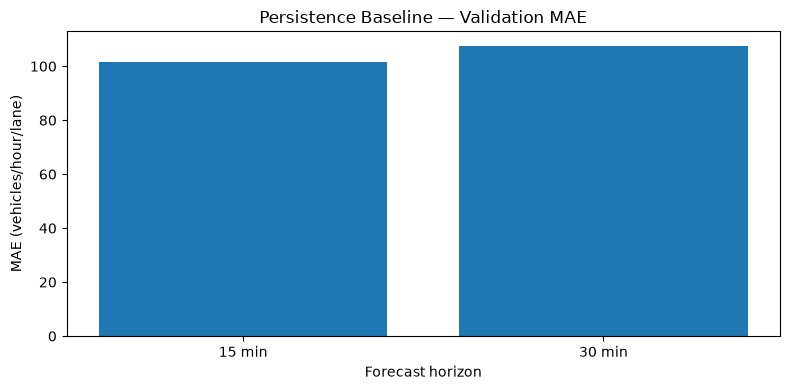

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))

validation_results = results_df[
    results_df["split"] == "validation"
]

ax.bar(
    validation_results["horizon"].astype(str) + " min",
    validation_results["MAE"],
)

ax.set_title("Persistence Baseline — Validation MAE")
ax.set_xlabel("Forecast horizon")
ax.set_ylabel("MAE (vehicles/hour/lane)")

plt.tight_layout()
plt.show()

In [9]:
# Only valid training measurements
train_history = df.loc[
    (df["split"] == "train") & df["flow"].notna()
]

# Average traffic flow for each detector, weekday, and hour
historical_avg = (
    train_history
    .groupby(["detid", "weekday", "hour"])["flow"]
    .mean()
    .rename("historical_flow")
    .reset_index()
)

print("Historical patterns:", len(historical_avg))
display(historical_avg.head())

Historical patterns: 13272


,detid,weekday,hour,historical_flow
0,ig11FD100_D3,0,0,68.742138
1,ig11FD100_D3,0,1,50.149254
2,ig11FD100_D3,0,2,24.859155
3,ig11FD100_D3,0,3,41.390728
4,ig11FD100_D3,0,4,62.320819


In [10]:
for horizon in [15, 30]:
    target = f"target_flow_{horizon}m"
    usable = f"usable_{horizon}m"

    # Use a small subset of columns
    subset = df.loc[
        df[usable],
        ["detid", "timestamp", "split", target]
    ].copy()

    # Determine future calendar features
    future_time = subset["timestamp"] + pd.Timedelta(minutes=horizon)

    subset["weekday"] = future_time.dt.dayofweek
    subset["hour"] = future_time.dt.hour

    # Attach historical averages learned from training
    subset = subset.merge(
        historical_avg,
        on=["detid", "weekday", "hour"],
        how="left",
        validate="many_to_one"
    )

    # Evaluate separately by split
    for split in ["train", "validation", "test"]:
        evaluation = subset.loc[
            (subset["split"] == split)
            & subset["historical_flow"].notna()
        ]

        results.append(
            evaluate_forecast(
                evaluation[target],
                evaluation["historical_flow"],
                model="Historical Average",
                horizon=horizon,
                split=split,
            )
        )

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        ["horizon", "split", "model"]
    )
)

,model,horizon,split,MAE,RMSE,samples
8,Historical Average,15,test,86.535812,112.687710,1363284
2,Persistence,15,test,99.991342,128.373664,1363284
6,Historical Average,15,train,81.776988,105.996295,6261815
0,Persistence,15,train,100.146316,128.681191,6261815
7,Historical Average,15,validation,80.700979,104.803906,1343994
1,Persistence,15,validation,101.460980,130.503564,1343994
11,Historical Average,30,test,85.868745,111.825759,1360422
5,Persistence,30,test,105.936999,136.603167,1360422
9,Historical Average,30,train,81.285061,105.453873,6248652
3,Persistence,30,train,105.767754,136.382968,6248652


horizon,15,30
model,,
Historical Average,80.70,80.24
Persistence,101.46,107.56


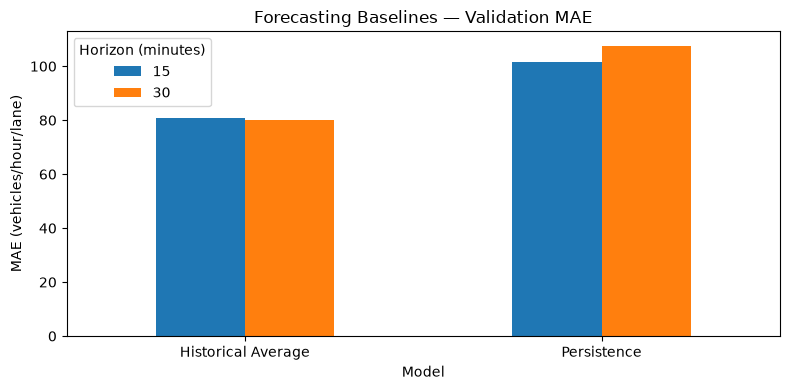

In [11]:
validation_comparison = (
    results_df[results_df["split"] == "validation"]
    .pivot(index="model", columns="horizon", values="MAE")
    .round(2)
)

display(validation_comparison)

validation_comparison.plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Forecasting Baselines — Validation MAE")
plt.xlabel("Model")
plt.ylabel("MAE (vehicles/hour/lane)")
plt.xticks(rotation=0)
plt.legend(title="Horizon (minutes)")
plt.tight_layout()
plt.show()

In [13]:
feature_columns = [
    "detector_code",
    "hour",
    "weekday",
    "minute",
    "flow",
    "occ",
    "flow_lag_1",
    "flow_lag_5",
    "flow_lag_10",
    "occ_lag_1",
    "occ_lag_5",
    "flow_roll_mean_5",
    "flow_roll_mean_10",
]

model_columns = [
    "detid", "timestamp", "split",
    "usable_15m", "usable_30m",
    "target_flow_15m", "target_flow_30m",
] + [
    c for c in feature_columns
    if c not in ["detector_code", "minute"]
]

detector_ids = sorted(df["detid"].unique())
detector_mapping = {
    detid: i for i, detid in enumerate(detector_ids)
}

In [14]:
ml_results = []
models = {}

for horizon in [15, 30]:
    print(f"\nTraining {horizon}-minute model...")

    target = f"target_flow_{horizon}m"
    usable = f"usable_{horizon}m"

    # Read only eligible training and validation records
    data = pd.read_parquet(
        DATA_PATH,
        columns=model_columns,
        filters=[
            ("split", "in", ["train", "validation"]),
            (usable, "=", True),
        ],
    )

    data["detector_code"] = (
        data["detid"].map(detector_mapping).astype("int16")
    )
    data["minute"] = data["timestamp"].dt.minute

    train = data.loc[data["split"] == "train"]
    val = data.loc[data["split"] == "validation"]

    # Sample training rows only
    train_sample = train.sample(
        n=min(300_000, len(train)),
        random_state=42
    )

    model = HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=31,
        categorical_features=[0],
        early_stopping=False,
        random_state=42
    )

    model.fit(
        train_sample[feature_columns],
        train_sample[target]
    )

    predictions = model.predict(val[feature_columns])

    ml_results.append(
        evaluate_forecast(
            val[target],
            predictions,
            model="HistGradientBoosting",
            horizon=horizon,
            split="validation",
        )
    )

    models[horizon] = model

    del data, train, val, train_sample, predictions
    gc.collect()

ml_results_df = pd.DataFrame(ml_results)
display(ml_results_df)


Training 15-minute model...

Training 30-minute model...


,model,horizon,split,MAE,RMSE,samples
0,HistGradientBoosting,15,validation,75.966076,97.283994,1343994
1,HistGradientBoosting,30,validation,76.821636,98.639109,1340719


In [15]:
comparison = pd.concat(
    [results_df, ml_results_df],
    ignore_index=True
)

validation = comparison[
    comparison["split"] == "validation"
]

display(
    validation.pivot(
        index="model",
        columns="horizon",
        values="MAE"
    ).round(2)
)

horizon,15,30
model,,
HistGradientBoosting,75.97,76.82
Historical Average,80.70,80.24
Persistence,101.46,107.56


In [16]:
peak_results = []

for horizon in [15, 30]:
    target = f"target_flow_{horizon}m"
    usable = f"usable_{horizon}m"

    cols = model_columns

    val = pd.read_parquet(
        DATA_PATH,
        columns=cols,
        filters=[
            ("split", "=", "validation"),
            (usable, "=", True),
        ],
    )

    val["detector_code"] = (
        val["detid"].map(detector_mapping).astype("int16")
    )
    val["minute"] = val["timestamp"].dt.minute

    target_time = val["timestamp"] + pd.Timedelta(minutes=horizon)
    val["target_hour"] = target_time.dt.hour
    val["target_weekday"] = target_time.dt.dayofweek

    val["period"] = np.select(
        [
            val["target_hour"].between(7, 8),
            val["target_hour"].between(16, 17),
        ],
        ["Morning", "Afternoon"],
        default="Other",
    )

    # Predictions from our ML model
    val["ml_prediction"] = models[horizon].predict(
        val[feature_columns]
    )

    # Persistence predictions
    val["persistence_prediction"] = val["flow"]

    # Historical average predictions
    val = val.merge(
        historical_avg,
        left_on=["detid", "target_weekday", "target_hour"],
        right_on=["detid", "weekday", "hour"],
        how="left",
        validate="many_to_one",
    )

    for period, group in val.groupby("period"):
        for name, prediction_col in [
            ("Persistence", "persistence_prediction"),
            ("Historical Average", "historical_flow"),
            ("HistGradientBoosting", "ml_prediction"),
        ]:
            valid = group[
                group[prediction_col].notna()
            ]

            peak_results.append({
                "horizon": horizon,
                "period": period,
                "model": name,
                "MAE": mean_absolute_error(
                    valid[target],
                    valid[prediction_col]
                ),
                "samples": len(valid),
            })

peak_df = pd.DataFrame(peak_results)

display(
    peak_df.pivot_table(
        index=["horizon", "period"],
        columns="model",
        values="MAE",
    ).round(2)
)

model              HistGradientBoosting  Historical Average  Persistence
horizon period                                                          
15      Afternoon                 84.52               88.97       109.50
        Morning                   79.99               87.99       106.22
        Other                     74.12               78.48        99.60
30      Afternoon                 86.24               89.27       113.23
        Morning                   82.42               88.47       116.32
        Other                     74.68               77.84       105.62

In [17]:
detector_results = []

for horizon in [15, 30]:
    target = f"target_flow_{horizon}m"
    usable = f"usable_{horizon}m"

    val = pd.read_parquet(
        DATA_PATH,
        columns=model_columns,
        filters=[
            ("split", "=", "validation"),
            (usable, "=", True),
        ],
    )

    val["detector_code"] = (
        val["detid"].map(detector_mapping).astype("int16")
    )
    val["minute"] = val["timestamp"].dt.minute

    # Predict with ML
    val["ml_pred"] = models[horizon].predict(
        val[feature_columns]
    )

    # Historical prediction at target time
    future_time = val["timestamp"] + pd.Timedelta(
        minutes=horizon
    )

    val["target_hour"] = future_time.dt.hour
    val["target_weekday"] = future_time.dt.dayofweek

    val = val.merge(
        historical_avg,
        left_on=["detid", "target_weekday", "target_hour"],
        right_on=["detid", "weekday", "hour"],
        how="left",
        validate="many_to_one",
    )

    val["ml_error"] = (
        val[target] - val["ml_pred"]
    ).abs()

    val["historical_error"] = (
        val[target] - val["historical_flow"]
    ).abs()

    per_detector = (
        val.groupby("detid")
        .agg(
            ml_mae=("ml_error", "mean"),
            historical_mae=("historical_error", "mean"),
            samples=("ml_error", "count"),
        )
        .reset_index()
    )

    per_detector["improvement_pct"] = (
        (
            per_detector["historical_mae"]
            - per_detector["ml_mae"]
        )
        / per_detector["historical_mae"]
        * 100
    )

    per_detector["horizon"] = horizon
    detector_results.append(per_detector)

detector_results_df = pd.concat(
    detector_results,
    ignore_index=True
)

display(
    detector_results_df.groupby("horizon").agg(
        detectors=("detid", "nunique"),
        improved_detectors=(
            "improvement_pct",
            lambda x: (x > 0).sum()
        ),
        median_improvement_pct=("improvement_pct", "median"),
        worst_improvement_pct=("improvement_pct", "min"),
        best_improvement_pct=("improvement_pct", "max"),
    ).round(2)
)

,detectors,improved_detectors,median_improvement_pct,worst_improvement_pct,best_improvement_pct
horizon,,,,,
15,79,76,5.41,-4.55,12.07
30,79,73,4.03,-4.39,10.79


In [18]:
sample_results = []

for horizon in [15, 30]:
    target = f"target_flow_{horizon}m"
    usable = f"usable_{horizon}m"

    data = pd.read_parquet(
        DATA_PATH,
        columns=model_columns,
        filters=[
            ("split", "in", ["train", "validation"]),
            (usable, "=", True),
        ],
    )

    data["detector_code"] = (
        data["detid"].map(detector_mapping).astype("int16")
    )
    data["minute"] = data["timestamp"].dt.minute

    train = data[data["split"] == "train"]
    val = data[data["split"] == "validation"]

    X_val = val[feature_columns]
    y_val = val[target]

    for sample_size in [300_000, 1_000_000]:
        train_sample = train.sample(
            n=sample_size,
            random_state=42
        )

        model = HistGradientBoostingRegressor(
            max_iter=100,
            learning_rate=0.1,
            max_leaf_nodes=31,
            categorical_features=[0],
            early_stopping=False,
            random_state=42
        )

        model.fit(
            train_sample[feature_columns],
            train_sample[target]
        )

        predictions = model.predict(X_val)

        sample_results.append({
            "horizon": horizon,
            "training_samples": sample_size,
            "MAE": mean_absolute_error(y_val, predictions),
            "RMSE": root_mean_squared_error(y_val, predictions),
        })

        del train_sample, model, predictions
        gc.collect()

    del data, train, val
    gc.collect()

sample_results_df = pd.DataFrame(sample_results)

display(sample_results_df)

,horizon,training_samples,MAE,RMSE
0,15,300000,75.966076,97.283994
1,15,1000000,75.758628,97.027567
2,30,300000,76.821636,98.639109
3,30,1000000,76.636583,98.403604


In [19]:
import joblib

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

final_models = {}

for horizon in [15, 30]:
    target = f"target_flow_{horizon}m"
    usable = f"usable_{horizon}m"

    train = pd.read_parquet(
        DATA_PATH,
        columns=model_columns,
        filters=[
            ("split", "=", "train"),
            (usable, "=", True),
        ],
    )

    train["detector_code"] = (
        train["detid"].map(detector_mapping).astype("int16")
    )
    train["minute"] = train["timestamp"].dt.minute

    train_sample = train.sample(
        n=1_000_000,
        random_state=42
    )

    model = HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=31,
        categorical_features=[0],
        early_stopping=False,
        random_state=42
    )

    model.fit(
        train_sample[feature_columns],
        train_sample[target]
    )

    final_models[horizon] = model

    joblib.dump(
        {
            "model": model,
            "features": feature_columns,
            "detector_mapping": detector_mapping,
            "horizon_minutes": horizon,
        },
        MODEL_DIR / f"traffic_forecast_{horizon}m.joblib"
    )

    print(f"Saved {horizon}-minute model")

    del train, train_sample
    gc.collect()

Saved 15-minute model
Saved 30-minute model


In [20]:
final_results = []

for horizon in [15, 30]:
    target = f"target_flow_{horizon}m"
    usable = f"usable_{horizon}m"

    test = pd.read_parquet(
        DATA_PATH,
        columns=model_columns,
        filters=[
            ("split", "=", "test"),
            (usable, "=", True),
        ],
    )

    test["detector_code"] = (
        test["detid"].map(detector_mapping).astype("int16")
    )
    test["minute"] = test["timestamp"].dt.minute

    predictions = final_models[horizon].predict(
        test[feature_columns]
    )

    final_results.append(
        evaluate_forecast(
            test[target],
            predictions,
            model="HistGradientBoosting",
            horizon=horizon,
            split="test",
        )
    )

    del test, predictions
    gc.collect()

final_test_df = pd.DataFrame(final_results)
display(final_test_df)

,model,horizon,split,MAE,RMSE,samples
0,HistGradientBoosting,15,test,75.492693,96.476837,1363284
1,HistGradientBoosting,30,test,76.943437,98.534912,1360422


In [21]:
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

all_results = pd.concat(
    [
        results_df,
        ml_results_df,
        final_test_df,
    ],
    ignore_index=True,
)

all_results.to_csv(
    RESULTS_DIR / "forecasting_baseline_results.csv",
    index=False
)

print("Results saved!")

Results saved!
